# 2. Geo holdout, lift estimation, and MMM calibration

Notebook 1 showed that the MMM overstates the return on search, because search spend
follows a demand shock the model cannot see. A randomized experiment breaks that link.

**Design.** 10 of 40 geos, chosen at random, turn off search for 7 weeks (weeks 130–136).
Spend elsewhere is unchanged. This mirrors the eBay paid-search experiment
(Blake, Nosko and Tadelis, 2015). Because treatment is assigned at random and the demand
shock is common to all geos, comparing treated and control geos over time recovers the
causal effect of search.

I estimate the lift two ways (difference-in-differences and synthetic control), compare
both with the true lift from the simulator, and then feed the experimental estimate into
the MMM as a lift-test likelihood.

In [1]:
import sys
import warnings

warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import xarray as xr
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
from scipy.optimize import minimize

from simulate import CHANNELS, default_holdout, simulate_world

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SAMPLER = dict(nuts_sampler="numpyro", chains=4, draws=1000, tune=1000, target_accept=0.95, progressbar=False)

In [2]:
design = default_holdout()
world = simulate_world(holdout=design)
counterfactual = simulate_world(holdout=None)
panel, nat, truth = world["panel"], world["national"], world["truth"]
design

{'channel': 'search',
 'geos': [1, 4, 5, 16, 18, 20, 21, 26, 31, 36],
 'start_week': 130,
 'end_week': 136}

Outcomes are in per-capita terms (geo sales divided by the geo's population share), so a
one-unit effect in a geo is directly comparable to a one-unit change in national weekly sales.

In [3]:
panel["sales_pc"] = panel["sales"] / panel["pop_share"]
panel["treated"] = panel["geo"].isin(design["geos"]).astype(int)
test_weeks = (panel["week"] >= design["start_week"]) & (panel["week"] <= design["end_week"])
panel["post"] = test_weeks.astype(int)

cf = counterfactual["panel"]
gap = (cf["search_true_contrib"] - panel["search_true_contrib"]) / panel["pop_share"]
true_lift = -gap[(panel["treated"] == 1) & test_weeks].mean()
print(f"true effect of turning search off: {true_lift:.1f} sales per week (national-equivalent)")

true effect of turning search off: -60.3 sales per week (national-equivalent)


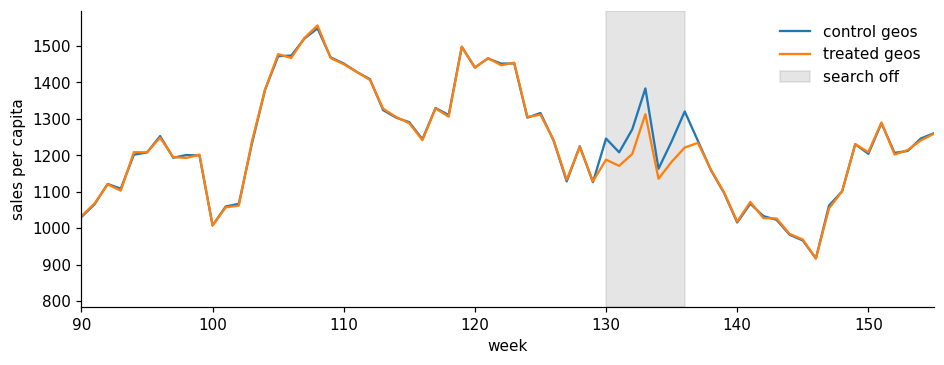

In [4]:
avg = panel.groupby(["week", "treated"])["sales_pc"].mean().unstack()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(avg.index, avg[0], label="control geos")
ax.plot(avg.index, avg[1], label="treated geos")
ax.axvspan(design["start_week"], design["end_week"], color="grey", alpha=0.2, label="search off")
ax.set_xlim(90, 155)
ax.set_xlabel("week")
ax.set_ylabel("sales per capita")
ax.legend(frameon=False)
fig.savefig("../figures/geo_raw.png", bbox_inches="tight")

## Difference-in-differences

Geo and week fixed effects, using the 26 weeks before the test as the pre-period and
dropping the weeks after it (carryover would contaminate them). Standard errors are
clustered by geo.

In [5]:
win = panel[(panel["week"] >= design["start_week"] - 26) & (panel["week"] <= design["end_week"])].copy()
win["treat_post"] = win["treated"] * win["post"]
did = smf.ols("sales_pc ~ treat_post + C(geo) + C(week)", data=win).fit(
    cov_type="cluster", cov_kwds={"groups": win["geo"]}
)
did_est, did_se = did.params["treat_post"], did.bse["treat_post"]
print(f"DiD: {did_est:.1f} (SE {did_se:.1f});  true: {true_lift:.1f}")

DiD: -59.4 (SE 1.6);  true: -60.3


Event-study version, to check that treated and control geos move together before the test.

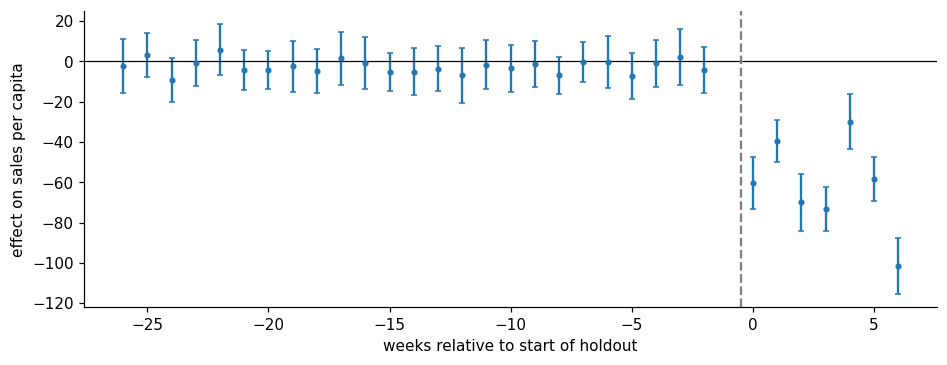

In [6]:
win["rel"] = win["week"] - design["start_week"]
ks = [k for k in range(-26, 7) if k != -1]
for k in ks:
    win[f"d{k + 26}"] = ((win["treated"] == 1) & (win["rel"] == k)).astype(int)
dummies = [f"d{k + 26}" for k in ks]
es = smf.ols("sales_pc ~ " + " + ".join(dummies) + " + C(geo) + C(week)", data=win).fit(
    cov_type="cluster", cov_kwds={"groups": win["geo"]}
)
coef, se = es.params[dummies].to_numpy(), es.bse[dummies].to_numpy()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.errorbar(ks, coef, yerr=1.96 * se, fmt="o", ms=3, capsize=2)
ax.axhline(0, color="black", lw=0.8)
ax.axvline(-0.5, color="grey", ls="--")
ax.set_xlabel("weeks relative to start of holdout")
ax.set_ylabel("effect on sales per capita")
fig.savefig("../figures/geo_event_study.png", bbox_inches="tight")

## Synthetic control

Build a weighted average of control geos that tracks the treated geos' average before the
test (non-negative weights summing to one), then read the effect off the gap during the test.

In [7]:
wide = panel.pivot(index="week", columns="geo", values="sales_pc")
treated_avg = wide[design["geos"]].mean(axis=1)
donors = wide.drop(columns=design["geos"])
pre = wide.index < design["start_week"]
test = (wide.index >= design["start_week"]) & (wide.index <= design["end_week"])

def loss(w):
    return ((treated_avg[pre] - donors[pre] @ w) ** 2).mean()

n = donors.shape[1]
res = minimize(loss, np.full(n, 1 / n), bounds=[(0, 1)] * n,
               constraints={"type": "eq", "fun": lambda w: w.sum() - 1}, method="SLSQP")
synth = donors @ res.x
sc_est = (treated_avg[test] - synth[test]).mean()

placebo = []
for g in donors.columns:
    others = donors.drop(columns=g)
    f = lambda w: ((donors[g][pre] - others[pre] @ w) ** 2).mean()
    r = minimize(f, np.full(n - 1, 1 / (n - 1)), bounds=[(0, 1)] * (n - 1),
                 constraints={"type": "eq", "fun": lambda w: w.sum() - 1}, method="SLSQP")
    placebo.append((donors[g][test] - others[test] @ r.x).mean())
placebo = np.array(placebo)
print(f"synthetic control: {sc_est:.1f};  placebo SD {placebo.std():.1f};  "
      f"share of placebos at least as extreme: {(np.abs(placebo) >= abs(sc_est)).mean():.2f}")

synthetic control: -59.6;  placebo SD 3.6;  share of placebos at least as extreme: 0.00


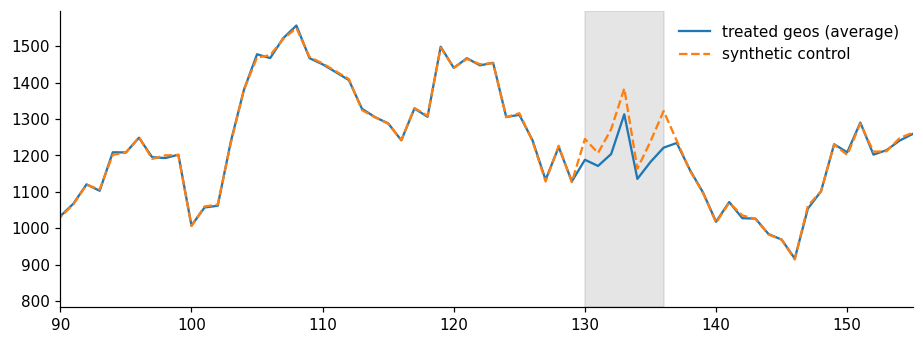

In [8]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(wide.index, treated_avg, label="treated geos (average)")
ax.plot(wide.index, synth, label="synthetic control", ls="--")
ax.axvspan(design["start_week"], design["end_week"], color="grey", alpha=0.2)
ax.set_xlim(90, 155)
ax.legend(frameon=False)
fig.savefig("../figures/synthetic_control.png", bbox_inches="tight")

In [9]:
lift = pd.DataFrame(
    {"estimate": [did_est, sc_est, true_lift], "se": [did_se, placebo.std(), np.nan]},
    index=["DiD", "synthetic control", "truth"],
).round(1)
lift

,estimate,se
DiD,-59.4,1.6
synthetic control,-59.6,3.6
truth,-60.3,NaN


## Calibrating the MMM with the experiment

PyMC-Marketing adds a lift test as an extra likelihood term: the model's saturation curve
must predict a change in sales of `delta_y` when spend moves from `x` to `x + delta_x`.
Here `x` is average weekly national search spend during the test, `delta_x = -x`
(search fully off), and `delta_y` is the DiD estimate with its standard error.

Two caveats. The lift test constrains the saturation curve at steady state and ignores
carryover, which is reasonable for search (true carryover is short) but would not be for TV.
And the experiment turned search off entirely, so it pins down the average return over the
whole curve, not the marginal return at current spend.

In [10]:
x_search = nat.loc[(nat["week"] >= design["start_week"]) & (nat["week"] <= design["end_week"]), "search"].mean()
treated_share = panel.loc[(panel["week"] == 0) & (panel["treated"] == 1), "pop_share"].sum()
x_full = x_search / (1 - treated_share)
df_lift = pd.DataFrame(
    {"channel": ["search"], "x": [x_full], "delta_x": [-x_full], "delta_y": [did_est], "sigma": [did_se]}
)
df_lift

,channel,x,delta_x,delta_y,sigma
0,search,19.367245,-19.367245,-59.433098,1.559472


In [11]:
X = nat[["date", *CHANNELS, "promo", "trend"]]
y = nat["sales"]
xr_spend = xr.DataArray(nat[CHANNELS].sum().to_numpy(), dims="channel", coords={"channel": CHANNELS})

mmm_cal = MMM(
    date_column="date",
    channel_columns=CHANNELS,
    control_columns=["promo", "trend"],
    adstock=GeometricAdstock(l_max=8),
    saturation=LogisticSaturation(),
    yearly_seasonality=2,
)
mmm_cal.build_model(X, y)
mmm_cal.add_lift_test_measurements(df_lift)
mmm_cal.fit(X, y, random_seed=1, **SAMPLER)
print("divergences:", int(mmm_cal.idata.sample_stats["diverging"].sum()))

roi_cal = (mmm_cal.compute_channel_contribution_original_scale().sum("date") / xr_spend)
roi_cal = roi_cal.stack(sample=("chain", "draw")).transpose("sample", "channel").to_pandas()
roi_uncal = pd.read_csv("../results/roi_uncalibrated_draws.csv")

There were 23 divergences after tuning. Increase `target_accept` or reparameterize.


divergences: 23


In [12]:
true_roi = truth.set_index("channel")["roi"]
rows = []
for label, s in [("uncalibrated", roi_uncal), ("calibrated with geo test", roi_cal)]:
    for c in CHANNELS:
        rows.append({"model": label, "channel": c, "p05": s[c].quantile(0.05), "median": s[c].median(),
                     "p95": s[c].quantile(0.95), "true_roi": true_roi[c]})
comparison = pd.DataFrame(rows).round(2)
comparison.to_csv("../results/roi_calibration_comparison.csv", index=False)
comparison

,model,channel,p05,median,p95,true_roi
0,uncalibrated,tv,2.54,2.91,3.31,2.68
1,uncalibrated,search,6.67,7.26,7.88,2.98
2,uncalibrated,social,0.66,2.22,11.63,1.20
3,calibrated with geo test,tv,3.17,3.69,4.28,2.68
4,calibrated with geo test,search,3.05,3.19,3.32,2.98
5,calibrated with geo test,social,0.48,2.46,11.47,1.20


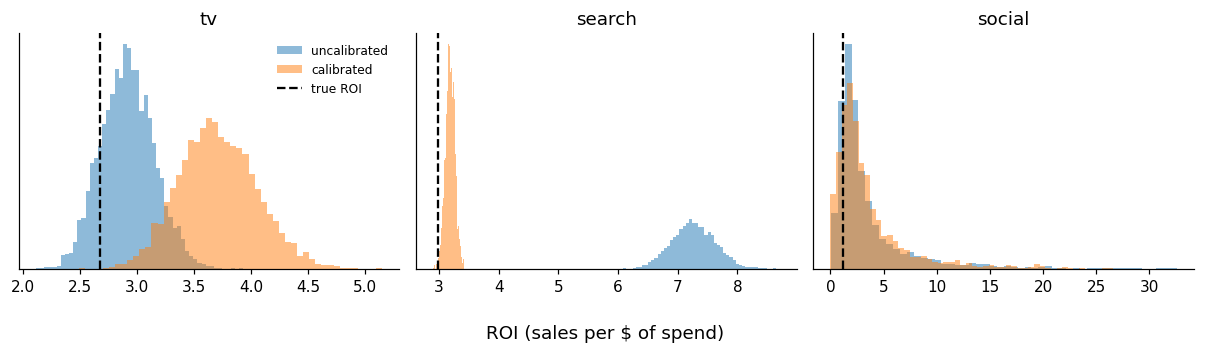

In [13]:
fig, axes = plt.subplots(1, len(CHANNELS), figsize=(11, 3.2))
for ax, c in zip(axes, CHANNELS):
    ax.hist(roi_uncal[c], bins=50, alpha=0.5, density=True, label="uncalibrated")
    ax.hist(roi_cal[c], bins=50, alpha=0.5, density=True, label="calibrated")
    ax.axvline(true_roi[c], color="black", ls="--", label="true ROI")
    ax.set_title(c)
    ax.set_yticks([])
axes[0].legend(frameon=False, fontsize=8)
fig.supxlabel("ROI (sales per $ of spend)")
fig.tight_layout()
fig.savefig("../figures/roi_calibrated.png", bbox_inches="tight")

## Takeaways

- **The experiment recovers the true lift.** Turning search off cost 60.3 sales per week
  (national-equivalent). DiD estimates 59.4 (SE 1.6) and synthetic control 59.6, and the
  event study shows flat pre-trends. The standard errors are tighter than a real geo test
  would give, because the simulated geos share one demand shock and have little
  idiosyncratic noise.
- **Calibration fixes search.** With the lift test added as a likelihood term, search ROI
  falls from 7.26 to 3.19 (90% interval 3.05–3.32) against a true 2.98. It is still slightly
  high, which is consistent with the lift test ignoring carryover.
- **The bias moves to TV.** Once search is pinned down, the model needs another channel to
  explain the demand-driven swings in sales, and TV, the other channel whose spend follows
  demand, absorbs them. TV ROI rises from 2.91 to 3.69 against a true 2.68, and the interval
  no longer covers the truth. One experiment calibrates one channel; every channel whose
  budget follows demand needs its own test, or the MMM needs a demand control.
- **Social is unchanged.** The experiment says nothing about it, and its interval stays wide.